# ASB Case Study 7B - News Topic Classification with Reuters Newswire

Note: This notebook was run in a cloud environment (Google Colab)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from keras import layers

In [2]:
SEED = 13
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 1 - Data inspection and tokenization

In [3]:
(X_train, y_train), (X_test, y_test) = keras.datasets.reuters.load_data(num_words=10000)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((8982,), (8982,), (2246,), (2246,))

In [4]:
print(f"Number of training articles: {len(X_train)}")
print(f"Number of test articles:     {len(X_test)}")
print(f"Shape of training labels:    {y_train.shape}")
print(f"Shape of test labels:        {y_test.shape}")
print(f"Number of unique topics:     {len(np.unique(y_train))}")
print("\nFirst training article (token IDs):\n", X_train[0])
print("\nFirst training label (topic ID):", y_train[0])

Number of training articles: 8982
Number of test articles:     2246
Shape of training labels:    (8982,)
Shape of test labels:        (2246,)
Number of unique topics:     46

First training article (token IDs):
 [1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]

First training label (topic ID): 3


## 2 - Sample conversion back to words

In [5]:
word_index = keras.datasets.reuters.get_word_index()

# Shift indices by +3 to account for reserved special tokens
reverse_word_index = {value + 3: key for key, value in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<OOV>"
reverse_word_index[3] = "<UNUSED>"

decoded_article = " ".join(
    reverse_word_index.get(token, "?") for token in X_train[0]
)

In [6]:
decoded_article

'<START> <OOV> <OOV> said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3'

## 3 - Inspect article lengths

In [7]:
article_lengths = [len(article) for article in X_train]

print("Lengths of first 10 articles:", article_lengths[:10])
print(f"Average length: {np.mean(article_lengths):.1f} tokens")
print(f"Median length:  {np.median(article_lengths):.1f} tokens")
print(f"Min length:     {np.min(article_lengths)} tokens")
print(f"Max length:     {np.max(article_lengths)} tokens")

Lengths of first 10 articles: [87, 56, 139, 224, 101, 116, 100, 100, 82, 106]
Average length: 145.5 tokens
Median length:  95.0 tokens
Min length:     13 tokens
Max length:     2376 tokens


## 4 - Pad and truncate text sequences

- Consider a max length of 200
- Articles shorter than 200 tokens get 0s appended to the end
- Articles longer than 200 tokens are cut off after the 200th token


In [8]:
max_length = 200

X_train_padded = keras.utils.pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = keras.utils.pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [9]:
print("X_train_padded shape:", X_train_padded.shape)
print("X_test_padded shape: ", X_test_padded.shape)
print("\nFirst padded article:\n", X_train_padded[0])

X_train_padded shape: (8982, 200)
X_test_padded shape:  (2246, 200)

First padded article:
 [   1    2    2    8   43   10  447    5   25  207  270    5 3095  111
   16  369  186   90   67    7   89    5   19  102    6   19  124   15
   90   67   84   22  482   26    7   48    4   49    8  864   39  209
  154    6  151    6   83   11   15   22  155   11   15    7   48    9
 4579 1005  504    6  258    6  272   11   15   22  134   44   11   15
   16    8  197 1245   90   67   52   29  209   30   32  132    6  109
   15   17   12    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0 

## 5 - Baseline NN

In [10]:
model_base = keras.Sequential([
    layers.Input(shape=(max_length,)),
    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(46, activation="softmax")
])

model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,014 (2.58 MB)

 Trainable params: 676,014 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile model
model_base.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
# Train model
history = model_base.fit(
    X_train_padded,
    y_train,
    validation_split=0.1,
    epochs=25,
    batch_size=64,
    verbose=1
)

Epoch 1/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 17s 116ms/step - accuracy: 0.3874 - loss: 2.5193 - val_accuracy: 0.4883 - val_loss: 2.0785
Epoch 2/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 14s 111ms/step - accuracy: 0.5121 - loss: 1.9436 - val_accuracy: 0.5284 - val_loss: 1.8359
Epoch 3/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.5472 - loss: 1.7622 - val_accuracy: 0.5662 - val_loss: 1.7151
Epoch 4/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.5653 - loss: 1.7269 - val_accuracy: 0.5951 - val_loss: 1.7359
Epoch 5/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.5912 - loss: 1.5998 - val_accuracy: 0.6085 - val_loss: 1.6180
Epoch 6/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.6340 - loss: 1.4638 - val_accuracy: 0.6352 - val_loss: 1.5569
Epoch 7/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 17s 137ms/step - accuracy: 0.6530 - loss: 1.3337 - val_accuracy: 0.6385 - val_loss: 1.4703
Epoch 8/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 19s 147ms/step - accuracy: 0.6747 - loss: 1

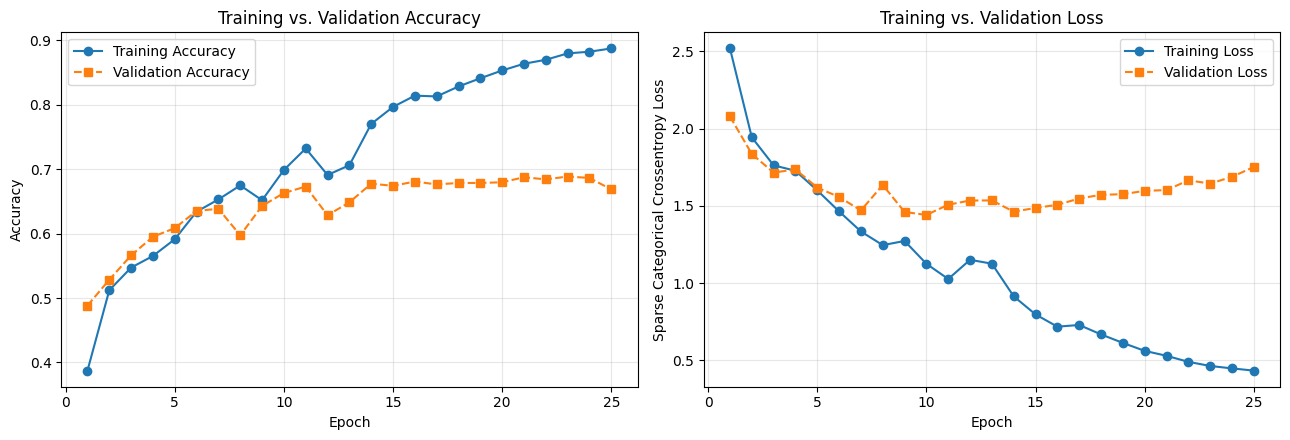

In [13]:
# Plot learning curves

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_range = range(1, len(history.history["accuracy"]) + 1)

# Plot 1: Accuracy
ax1.plot(epochs_range, history.history["accuracy"], "o-", label="Training Accuracy")
ax1.plot(epochs_range, history.history["val_accuracy"], "s--", label="Validation Accuracy")
ax1.set_title("Training vs. Validation Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Loss
ax2.plot(epochs_range, history.history["loss"], "o-", label="Training Loss")
ax2.plot(epochs_range, history.history["val_loss"], "s--", label="Validation Loss")
ax2.set_title("Training vs. Validation Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Sparse Categorical Crossentropy Loss")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()

Remarks:

- Training accuracy improved over time, while validation accuracy rised up to about 68% at epoch 14 and then plateaued in the succeeding epochs.
- There is a clear sign of overfitting starting at epoch 8. While training accuracy continues to go up and training loss continues to go down, validation accuracy continues to flatten and the loss gradually increases.
- We can say that validation performance stopped improving at epoch 14 by looking at accuracy, but we take note that validation loss stopped decreasing by epoch 8.

In [14]:
# Evaluate baseline

test_loss, test_accuracy = model_base.evaluate(X_test_padded, y_test, verbose=0)

print(f"Baseline Test Loss:     {test_loss:.4f}")
print(f"Baseline Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

Baseline Test Loss:     1.7248
Baseline Test Accuracy: 0.6643 (66.43%)


In [15]:
# Inspect predictions using baseline

predictions = model_base.predict(X_test_padded, verbose=0)

def decode_snippet(token_ids, max_words=35):
    words = [reverse_word_index.get(t, "?") for t in token_ids if t != 0]
    return " ".join(words[:max_words]) + ("..." if len(words) > max_words else "")

# Inspect a few test examples (including correct and incorrect predictions)
sample_indices = [0, 1, 3, 5]

for idx in sample_indices:
    pred_class = np.argmax(predictions[idx])
    confidence = np.max(predictions[idx])
    actual_class = y_test[idx]
    status = "CORRECT" if pred_class == actual_class else "INCORRECT"

    print(f"--- Test Article #{idx} [{status}] ---")
    print(f"Snippet:         {decode_snippet(X_test[idx])}")
    print(f"Actual Topic:    {actual_class}")
    print(f"Predicted Topic: {pred_class} (Confidence: {confidence:.2%})\n")

--- Test Article #0 [CORRECT] ---
Snippet:         <START> the great atlantic and pacific tea co said its three year 345 mln dlr capital program will be be substantially increased to <OOV> growth and expansion plans for <OOV> inc and <OOV> inc over...
Actual Topic:    3
Predicted Topic: 3 (Confidence: 57.63%)

--- Test Article #1 [INCORRECT] ---
Snippet:         <START> philippine sugar production in the 1987 88 crop year ending august has been set at 1 6 mln tonnes up from a provisional 1 3 mln tonnes this year sugar regulatory administration <OOV> chairman...
Actual Topic:    10
Predicted Topic: 17 (Confidence: 7.85%)

--- Test Article #3 [CORRECT] ---
Snippet:         <START> <OOV> <OOV> oil and gas partnership said it completed the sale of interests in two major oil and gas fields to lt energy assets international corp for 21 mln dlrs the company said it...
Actual Topic:    4
Predicted Topic: 4 (Confidence: 99.73%)

--- Test Article #5 [CORRECT] ---
Snippet:         <START> shr 12 

## 6 - Model improvement

- Add early stopping
- Add a dense layer
- Increase embedding size
- Change dropout
- Use Global Average Pooling (GAP)

In [18]:
# Build the GAP model
model_gap = keras.Sequential([
    layers.Input(shape=(max_length,)),

    # Expand embedding to 128 dims to capture finer topic distinctions
    layers.Embedding(
        input_dim=10000,
        output_dim=128,
        mask_zero=True
    ),

    # Average all non-padded word vectors into a single 128-dim article vector
    layers.GlobalAveragePooling1D(),

    # Add a hidden Dense layer to learn non-linear topic combinations
    layers.Dense(64, activation="relu"),

    # Regularize the hidden representation before final classification
    layers.Dropout(0.5),

    # 46-class probability output
    layers.Dense(46, activation="softmax")
])

model_gap.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 46)             │         2,990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,291,246 (4.93 MB)

 Trainable params: 1,291,246 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model_gap.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_gap = model_gap.fit(
    X_train_padded,
    y_train,
    validation_split=0.1,
    epochs=25,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.4646 - loss: 2.5247 - val_accuracy: 0.5106 - val_loss: 1.8615
Epoch 2/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5603 - loss: 1.7483 - val_accuracy: 0.6107 - val_loss: 1.5923
Epoch 3/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6423 - loss: 1.5014 - val_accuracy: 0.6963 - val_loss: 1.4074
Epoch 4/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6973 - loss: 1.2846 - val_accuracy: 0.7030 - val_loss: 1.2637
Epoch 5/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7256 - loss: 1.1413 - val_accuracy: 0.7175 - val_loss: 1.1789
Epoch 6/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7444 - loss: 1.0265 - val_accuracy: 0.7419 - val_loss: 1.1287
Epoch 7/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7691 - loss: 0.9360 - val_accuracy: 0.7508 - val_loss: 1.0850
Epoch 8/25
127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7865 - loss: 0.8489 - val_accu

In [20]:
loss_gap, acc_gap = model_gap.evaluate(X_test_padded, y_test, verbose=0)
print(f"Global Average Pooling Test Accuracy: {acc_gap:.4f} (Loss: {loss_gap:.4f})")

Global Average Pooling Test Accuracy: 0.7792 (Loss: 0.9298)


In [21]:
# Using the same example as before in making predictions using the model with GAP

predictions = model_gap.predict(X_test_padded, verbose=0)

def decode_snippet(token_ids, max_words=35):
    words = [reverse_word_index.get(t, "?") for t in token_ids if t != 0]
    return " ".join(words[:max_words]) + ("..." if len(words) > max_words else "")

# Inspect a few test examples (including correct and incorrect predictions)
sample_indices = [0, 1, 3, 5]

for idx in sample_indices:
    pred_class = np.argmax(predictions[idx])
    confidence = np.max(predictions[idx])
    actual_class = y_test[idx]
    status = "CORRECT" if pred_class == actual_class else "INCORRECT"

    print(f"--- Test Article #{idx} [{status}] ---")
    print(f"Snippet:         {decode_snippet(X_test[idx])}")
    print(f"Actual Topic:    {actual_class}")
    print(f"Predicted Topic: {pred_class} (Confidence: {confidence:.2%})\n")

--- Test Article #0 [CORRECT] ---
Snippet:         <START> the great atlantic and pacific tea co said its three year 345 mln dlr capital program will be be substantially increased to <OOV> growth and expansion plans for <OOV> inc and <OOV> inc over...
Actual Topic:    3
Predicted Topic: 3 (Confidence: 52.05%)

--- Test Article #1 [CORRECT] ---
Snippet:         <START> philippine sugar production in the 1987 88 crop year ending august has been set at 1 6 mln tonnes up from a provisional 1 3 mln tonnes this year sugar regulatory administration <OOV> chairman...
Actual Topic:    10
Predicted Topic: 10 (Confidence: 54.31%)

--- Test Article #3 [CORRECT] ---
Snippet:         <START> <OOV> <OOV> oil and gas partnership said it completed the sale of interests in two major oil and gas fields to lt energy assets international corp for 21 mln dlrs the company said it...
Actual Topic:    4
Predicted Topic: 4 (Confidence: 75.36%)

--- Test Article #5 [CORRECT] ---
Snippet:         <START> shr 12 c

Remarks:

- GAP trades sequential word-order processing for a wider semantic vocabulary space and a non-linear dense classifier head, delivering the highest accuracy and fastest training speed on small-to-medium text datasets.
- It simply averages all word embeddings in an article into a single 64-dimensional vector, completely ignoring word order. This case is applicable for our problem as news topic classification is driven primarily by vocabulary clusters.
- The use of LSTM matters if word order is important.



## 7 - Discussion

**1. Why can't raw words be passed directly into the neural network?**

Neural networks perform matrix multiplications and gradient calculations on numerical tensors; raw text strings have no inherent mathematical operations defined on them.

**2. What is the purpose of the Embedding layer?**

It translates discrete integer word IDs into dense, low-dimensional continuous vectors whose coordinates are learned during training so semantically related words have similar vector representations.

**3. What role does the LSTM play in processing an article?**

It processes the sequence of word embeddings step-by-step while maintaining an internal memory state, allowing the model to capture word order and contextual phrases rather than treating an article as an unordered bag of words.

**4. What change did you make to the baseline model?**

- Add early stopping
- Add a dense layer
- Increase embedding size
- Change dropout
- Use Global Average Pooling (GAP) instead of LSTM

**5. What happened after making the change?**

- Early stopping at epoch 16, with the weights in epoch 13 being the best
- Using GAP significantly decrease training time
- Massive improvement in accuracy from 0.6643 to 0.7792

**6. What was the most interesting thing I learned?**

Seeing how 95% of the model's trainable parameters sit inside the Embedding lookup table rather than the LSTM itself and watching how validation loss catches overconfidence/overfitting several epochs before validation accuracy visibly drops.